# TERRA Benchmarking

- Creators: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 30.06.2025
- Date of Last Modification: 05.04.2026 (by Sebastian Birk (sb75@sanger.ac.uk)

Run this notebook in the nichejepa environment:  <br>
```source /nfs/users/nfs_s/sb75/.venvs/nichejepa/bin/activate```

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [107]:
import gc
import logging
import os
import warnings

import anndata as ad
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import scipy.sparse as sp
import sklearn.metrics as skm
import torch
try:
    import squidpy as sq
except:
    print("Could not import squidpy")
    import rapids_singlecell as rsc
from datasets import concatenate_datasets, load_from_disk
from itertools import combinations
from matplotlib.colors import Normalize
from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from app.inference import (embed_dataset,
                           harmonize_adata,
                           perturb_dataset,
                           tokenize_adata,
                           harmonize_tokenize_embed_pipeline,
                           get_gene_embed,
                           get_average_gene_embed,
                           get_spatial_score,
                           get_emd_distance)
from app.utils import init_model, load_checkpoint
from nichejepa.utils.evaluation import (get_top_gene_score,
                                        get_top_gene_pairs)

from analysis_utils import *

### 1.2 Configure Paths

In [17]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

cache_directory_path = f'{benchmarking_artifacts_folder_path}/{method}/cache'
model_folder_path = f'{artifacts_folder_path}/models/{model_timestamp}'

### 1.3 Define Config

In [22]:
method = 'terra'

# General params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
label_keys = [niche_key]
species = 'mouse'
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'
n_pcs = None

# Terra params
model_timestamp = '21032026_085513_196'
emb_key = 'neighborhood_emb'
sample_key = None
min_cells_per_gene = 0
min_genes_per_cell = 10
nproc = 4
processing_mode = 'parallel'
use_generator = True
num_shards = 32
ensembl_release = 110
gene_mapping_dict_file_path = None
gene_occurrence_count_file_path = None
gene_occurrence_count_filter_value = 10
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_genes = None
top_k = None
batch_key_new = 'batch_new'

# Clustering params
latent_leiden_resolution = 1.3

### 1.4 Run Notebook Setup

In [6]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

pd.options.future.infer_string = False

In [9]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [10]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}/cache', exist_ok=True)

### 1.5 Define Functions

In [26]:
def make_large_cmap(n):
    base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"
    return [mcolors.to_hex(base(i)) for i in range(n)]

In [105]:
def mmd(X, Y, gamma=1.0):
    XX = np.exp(-gamma * cdist(X, X, 'sqeuclidean')).mean()
    YY = np.exp(-gamma * cdist(Y, Y, 'sqeuclidean')).mean()
    XY = np.exp(-gamma * cdist(X, Y, 'sqeuclidean')).mean()
    return XX + YY - 2 * XY

## 2. Analysis

### 2.1 Retrieve Embeddings

In [13]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/merge.py:1434: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [18]:
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=sample_key,
    batch_key=batch_key_new,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    gene_mapping_dict_file_path=gene_mapping_dict_file_path,
    gene_occurrence_count_file_path=gene_occurrence_count_file_path,
    gene_occurrence_count_filter_value=gene_occurrence_count_filter_value,
    ensembl_release=ensembl_release,
    species=species,
    gene_perturb_df=None,               
    nproc=nproc,
    processing_mode=processing_mode,
    harmonized_adata_save_path=f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}.h5ad",
    save_dataset_path=f"{benchmarking_artifacts_folder_path}/{method}/{model_timestamp}/{dataset_name}.dataset",
    num_shards=num_shards,
    emb_layer=emb_layer,
    agg_excluded_genes=agg_excluded_genes,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    use_generator=use_generator,
    add_neigh_cell_ids=False,
    min_cells_per_gene=min_cells_per_gene,
    min_genes_per_cell=min_genes_per_cell)

No `sample_key` specified. Start processing entire AnnData. This is the intended behavior if the AnnData object contains only one sample. Otherwise please specify a `sample_key` or results will be invalid!!!
Harmonizing AnnData...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
✓ adata.X contains raw counts (integer values).
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...
Make sure this ensembl release is aligned with pretraining.
Current ensembl release used for pretraining is 111.


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCm39/ensembl110/Mus_musculus.GRCm39.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCm39/ensembl110/Mus_musculus.GRCm39.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCm39/ensembl110/Mus_musculus.GRCm39.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs: 431.
Number of genes skipped due to non-matching ensembl IDs: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 10 genes.
Before cell filtering: 85704 cells.
After cell filtering: 85704 cells (removed 0 cells).
Filtering genes expressed in less than 0 cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/21032026_085513_196/token_dictionary.pkl.


Before gene filtering: 431 genes.
After gene filtering: 431 genes (removed 0 genes).
Harmonized AnnData.
Tokenizing AnnData.
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:678: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


... (7 outputs left out)

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:626: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 300 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/21032026_085513_196/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/inference/embed.py:255: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
670it [05:31,  2.02it/s]


Embedded tokenized data.


In [20]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.2 Visualize UMAP

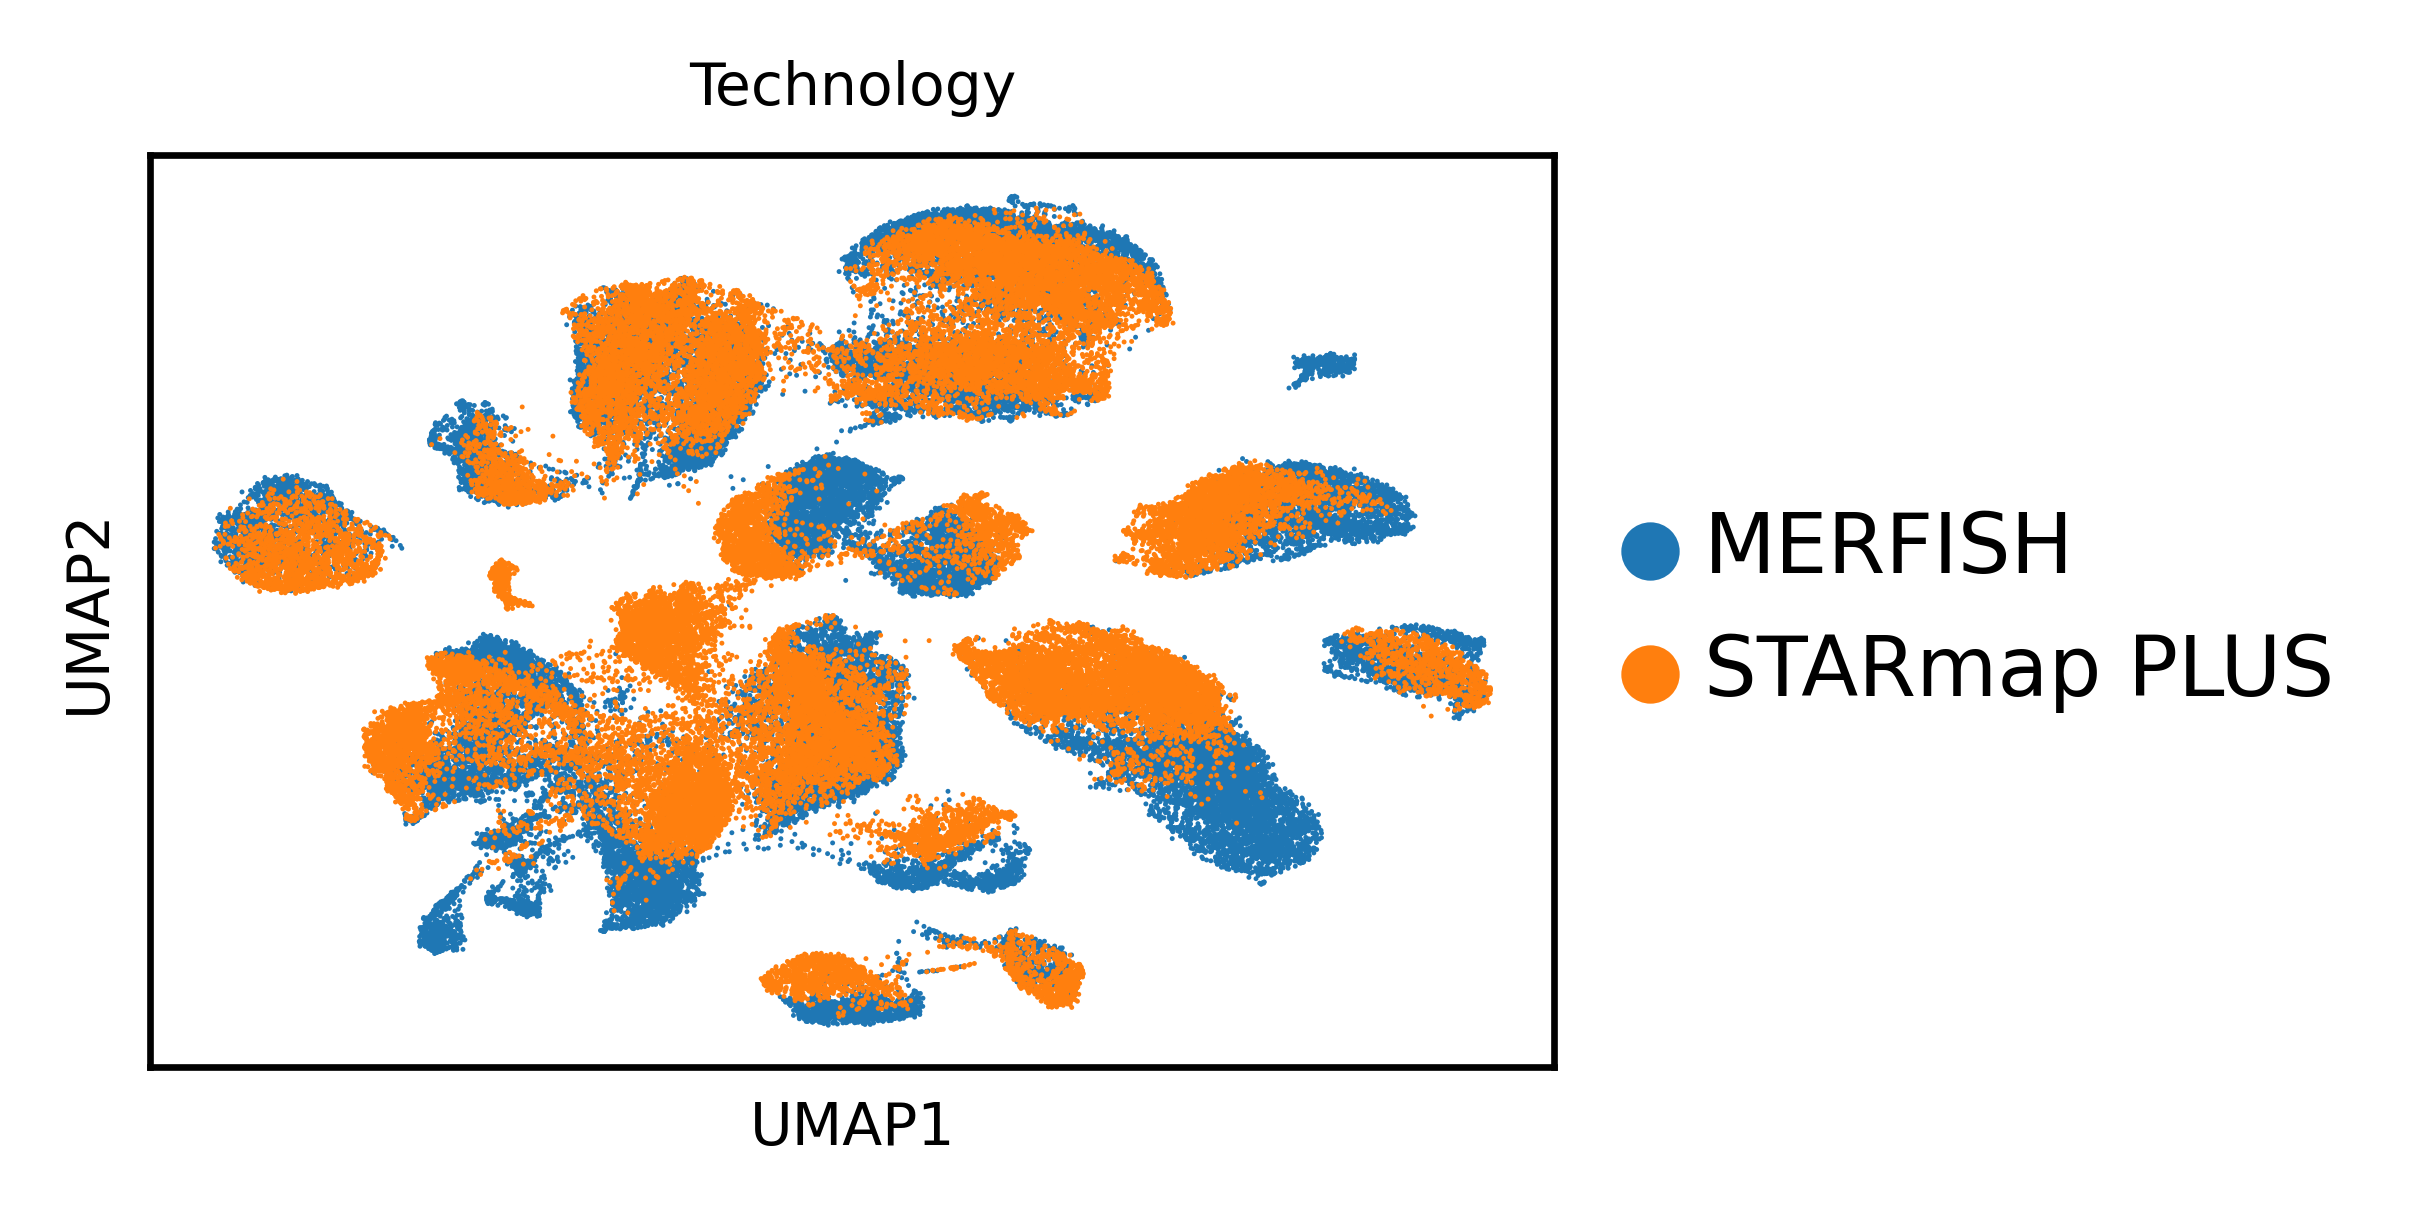

/tmp/ipykernel_1471414/3447051690.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"


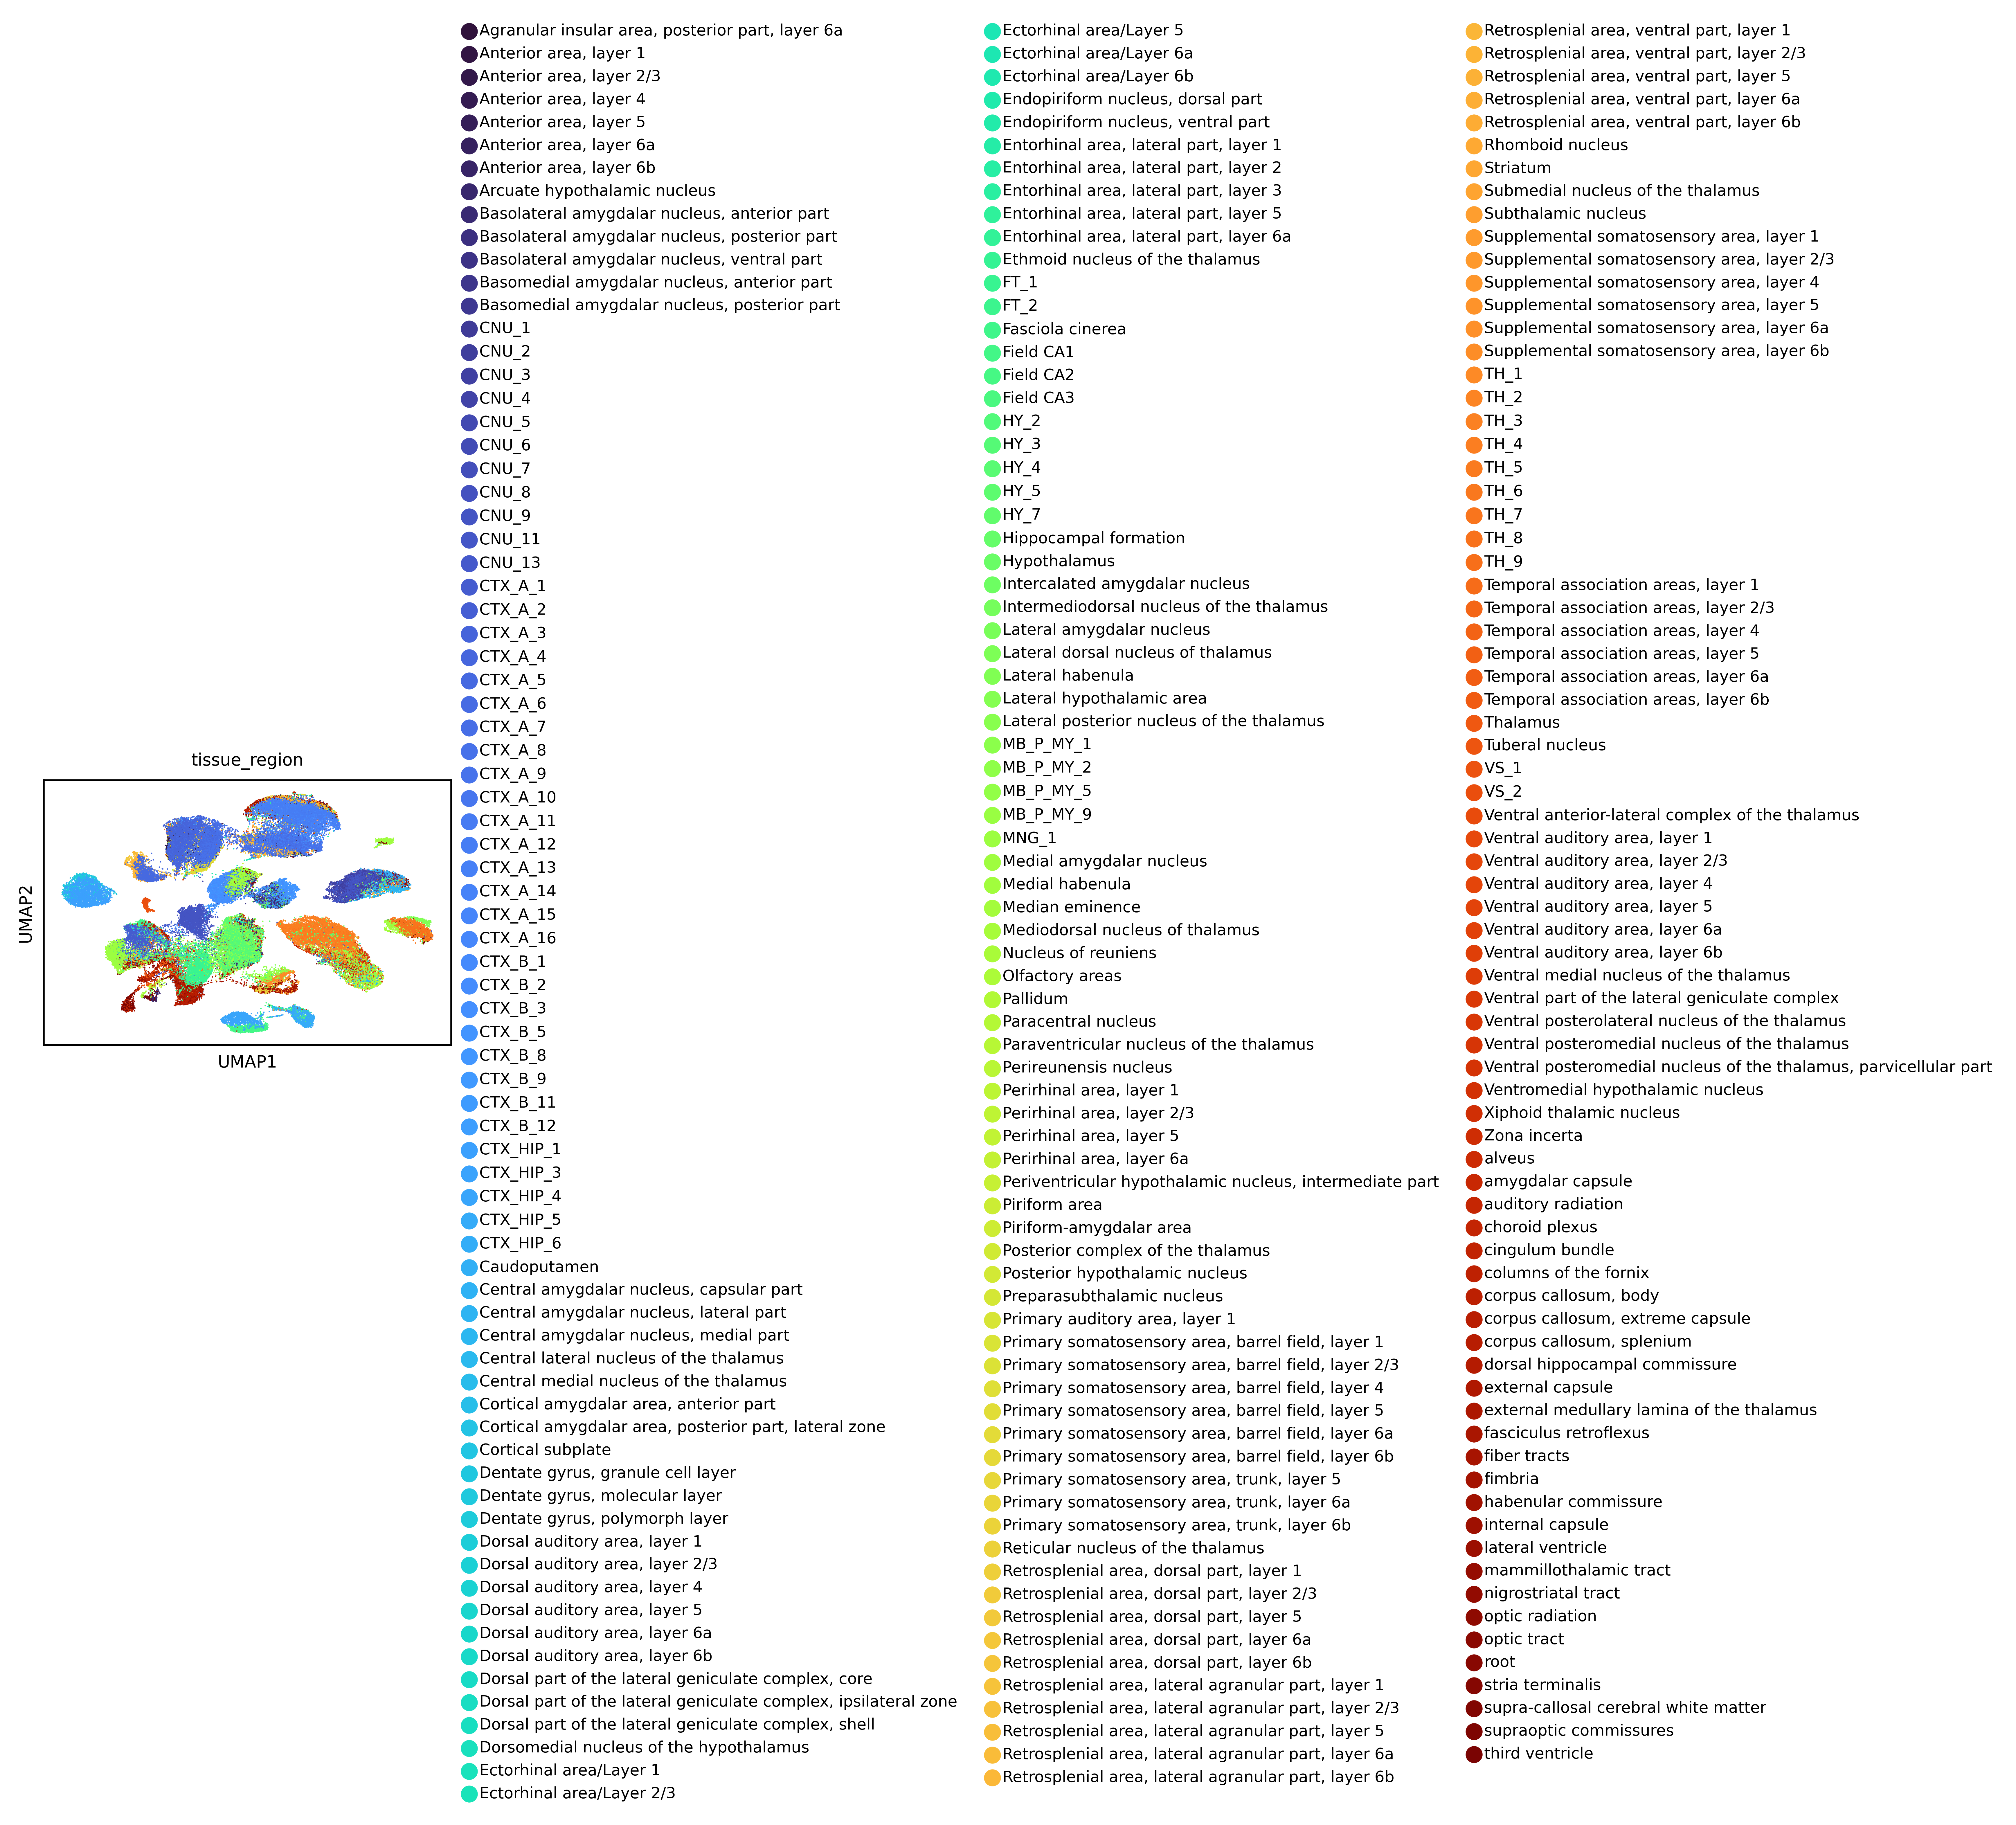

In [28]:
try:
    rsc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                     n_pcs=n_pcs, key_added=emb_key)
    rsc.tl.umap(adata, neighbors_key=emb_key)
except NameError:
    sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                    n_pcs=n_pcs, key_added=emb_key)
    sc.tl.umap(adata, neighbors_key=emb_key)

n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
adata.obs[batch_key] = adata.obs[batch_key].astype('category')
categories = adata.obs[batch_key].cat.categories.tolist()
assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

sc.pl.umap(
    adata,
    color=batch_key,
    title="Technology",
    legend_loc="right margin",
    legend_fontsize=10,
    show=False,
)
for collection in plt.gca().collections:
    collection.set_rasterized(True)
plt.savefig(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
    format="svg", bbox_inches="tight"
)
plt.show()
plt.close()

for label_key in label_keys:
    n_cats = adata.obs[label_key].nunique()
    palette = make_large_cmap(n_cats)
    sc.pl.umap(adata, color=label_key, palette=palette, show=False)
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [29]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.3 Visualize Niches

In [113]:
# Plot embedding-based clusters
latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"

try:
    rsc.tl.leiden(adata,
                  neighbors_key=emb_key,
                  key_added=latent_cluster_key,
                  resolution=latent_leiden_resolution,
                  flavor="igraph",
                  n_iterations=2)
except NameError:
    sc.tl.leiden(adata,
                 neighbors_key=emb_key,
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution,
                 flavor="igraph",
                 n_iterations=2)

In [114]:
print(adata.obs[latent_cluster_key].nunique())
print(adata.obs[latent_cluster_key].value_counts())

31
neighborhood_emb_clusters_res_1.3
16    8264
13    5910
8     5728
11    5597
9     5229
17    4719
6     4334
5     4033
1     3465
24    3251
14    3116
29    3088
23    2881
12    2873
4     2857
0     2507
7     2377
28    2341
15    2120
21    1972
30    1917
26    1911
25    1274
2     1092
18    1005
19     473
22     363
20     328
10     328
27     317
3       34
Name: count, dtype: int64


In [116]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded_clustered.h5ad')

/tmp/ipykernel_1471414/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_utils.py:481: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


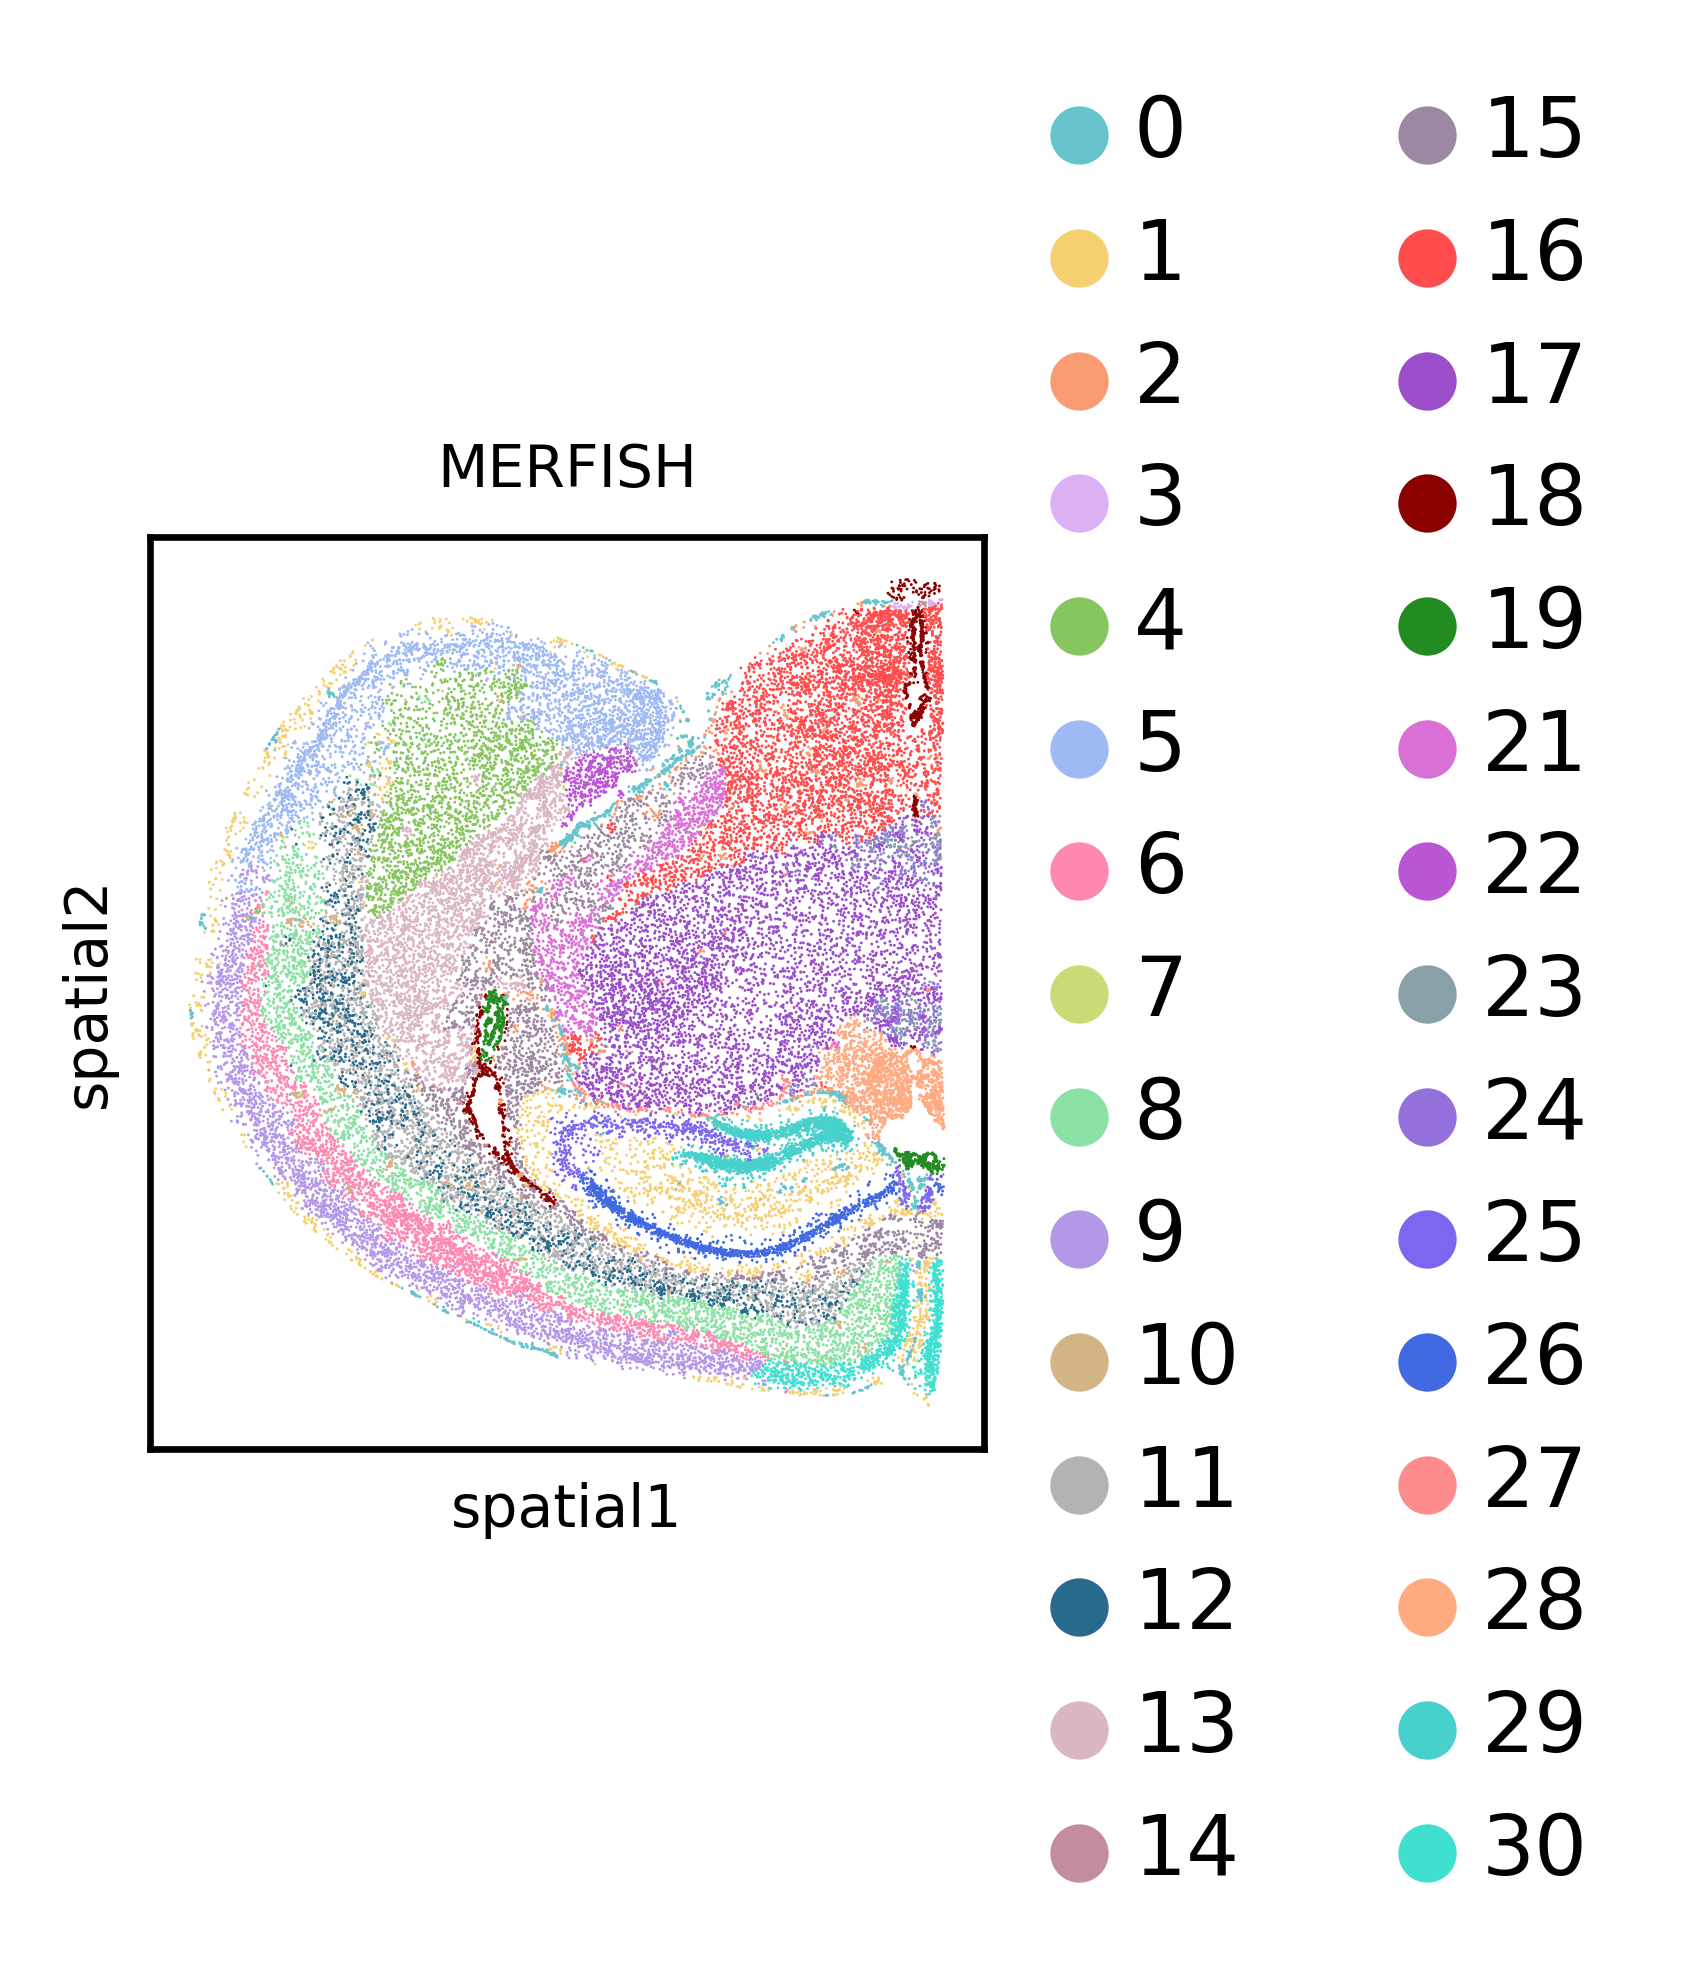

/tmp/ipykernel_1471414/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_utils.py:481: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


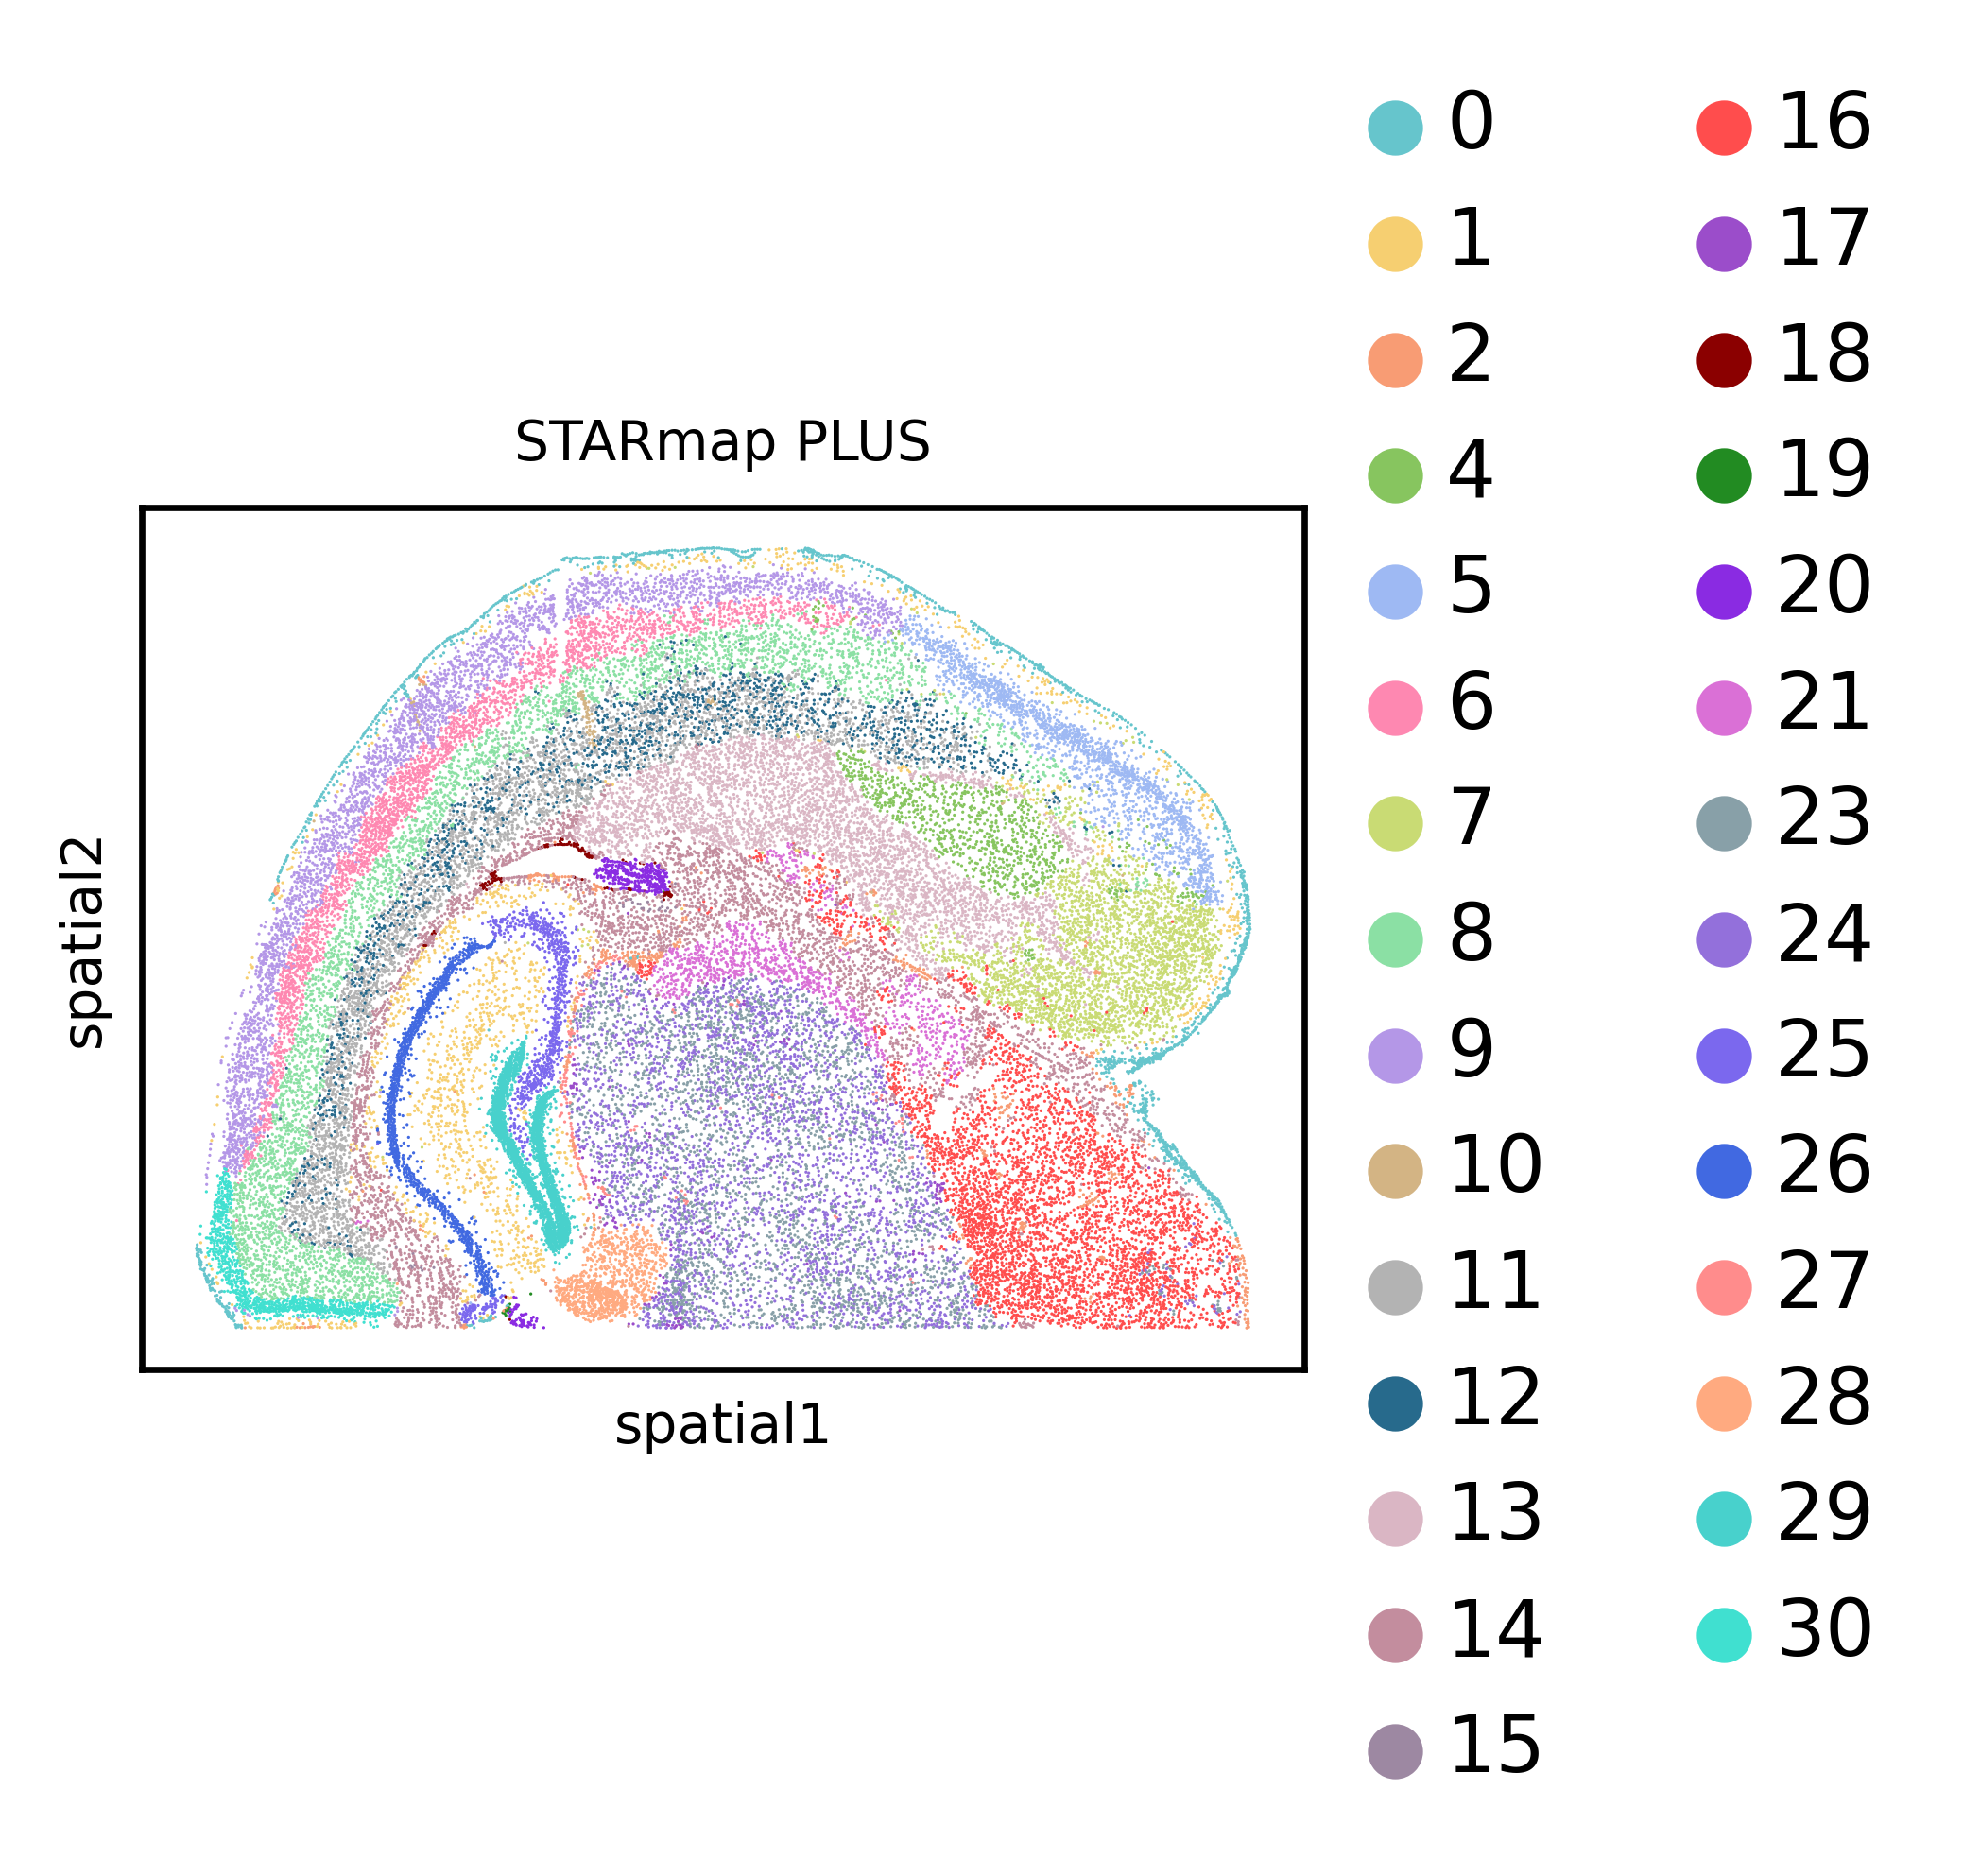

In [99]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

### 2.4 Compute Metrics

In [109]:
# Compute NMI and ARI with region annotations
results = []
for region_key in ["Sub_molecular_tissue_region", "ccf_region_name"]:
    mask = adata.obs[region_key].notna()
    labels_true = adata.obs.loc[mask, region_key]
    labels_pred = adata.obs.loc[mask, latent_cluster_key]
    nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
    ari = skm.adjusted_rand_score(labels_true, labels_pred)
    print(f"NMI ({region_key}): {nmi:.4f}")
    print(f"ARI ({region_key}): {ari:.4f}")
    results.append({"region_key": region_key, "NMI": nmi, "ARI": ari})

df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{latent_cluster_key}_niche_identification_metrics.csv",
    index=False
)

NMI (Sub_molecular_tissue_region): 0.7067
ARI (Sub_molecular_tissue_region): 0.4371
NMI (ccf_region_name): 0.6064
ARI (ccf_region_name): 0.2398


In [108]:
# Compute batch integration metrics
results = []

# iLISI
batch = adata.obs[batch_key].values
knn = pynndescent(adata.obsm[emb_key], n_neighbors=90)
ilisi = float(np.mean(ilisi_knn(knn, batch)))
print(f"iLISI: {ilisi:.4f}")
results.append({"metric": "iLISI", "score": ilisi})

# ASW
asw = silhouette_score(
    adata.obsm[emb_key],
    adata.obs["batch"],
    metric="euclidean",
    sample_size=10000
)
print(f"ASW batch: {asw:.4f}")
results.append({"metric": "ASW", "score": asw})

# MMD
batches = adata.obs[batch_key].unique()
b0 = adata[adata.obs[batch_key] == batches[0]].obsm[emb_key]
b1 = adata[adata.obs[batch_key] == batches[1]].obsm[emb_key]
idx0 = np.random.choice(len(b0), min(2000, len(b0)), replace=False)
idx1 = np.random.choice(len(b1), min(2000, len(b1)), replace=False)
mmd_score = mmd(b0[idx0], b1[idx1])
print(f"MMD: {mmd_score:.4f}")
results.append({"metric": "MMD", "score": mmd_score})

# Save
df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_batch_integration_metrics.csv",
    index=False
)

iLISI: 0.1071
ASW batch: 0.0188
MMD: 0.0010


In [112]:
# --- Config -----------------------------------------------------------
N_STEPS   = 4      # points above and below base resolution
STEP_SIZE = 0.1
MIN_RES   = 0.1    # Leiden resolution must be > 0

region_keys = ["Sub_molecular_tissue_region", "ccf_region_name"]

# Build resolution grid: N_STEPS below and above base, clamped to MIN_RES
# Use integer steps to avoid float accumulation errors in np.arange
base_int = round(latent_leiden_resolution / STEP_SIZE)  # e.g. 1.0/0.1 -> 10
resolutions = [
    round(step * STEP_SIZE, 1)
    for step in range(base_int - N_STEPS, base_int + N_STEPS + 1)
    if step * STEP_SIZE >= MIN_RES
]

# --- Sweep ------------------------------------------------------------
all_results = []

for res in resolutions:
    cluster_key = f"{emb_key}_clusters_res_{res}"

    # Leiden clustering
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=cluster_key,
                      resolution=res,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=emb_key,
                     key_added=cluster_key,
                     resolution=res,
                     flavor="igraph",
                     n_iterations=2)

    n_clusters = adata.obs[cluster_key].nunique()
    print(f"\n── Resolution {res:.1f}  ({n_clusters} clusters) ──")

    for region_key in region_keys:
        mask        = adata.obs[region_key].notna()
        labels_true = adata.obs.loc[mask, region_key]
        labels_pred = adata.obs.loc[mask, cluster_key]

        nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
        ari = skm.adjusted_rand_score(labels_true, labels_pred)
        print(f"  {region_key:40s}  NMI={nmi:.4f}  ARI={ari:.4f}")

        all_results.append({
            "resolution": res,
            "n_clusters": n_clusters,
            "region_key": region_key,
            "NMI":        nmi,
            "ARI":        ari,
        })

# --- Save -------------------------------------------------------------
df = pd.DataFrame(all_results)

# Canonical column order
df = df[["resolution", "n_clusters", "region_key", "NMI", "ARI"]]

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_niche_identification_metrics_res_sweep.csv"
)
df.to_csv(out_path, index=False)
print(f"\nSaved {len(df)} rows → {out_path}")


── Resolution 0.9  (25 clusters) ──
  Sub_molecular_tissue_region               NMI=0.7225  ARI=0.4627
  ccf_region_name                           NMI=0.6117  ARI=0.2252

── Resolution 1.0  (27 clusters) ──
  Sub_molecular_tissue_region               NMI=0.7226  ARI=0.4614
  ccf_region_name                           NMI=0.6128  ARI=0.2287

── Resolution 1.1  (27 clusters) ──
  Sub_molecular_tissue_region               NMI=0.7199  ARI=0.4701
  ccf_region_name                           NMI=0.6095  ARI=0.2366

── Resolution 1.2  (29 clusters) ──
  Sub_molecular_tissue_region               NMI=0.7175  ARI=0.4674
  ccf_region_name                           NMI=0.6065  ARI=0.2378

── Resolution 1.3  (31 clusters) ──
  Sub_molecular_tissue_region               NMI=0.7067  ARI=0.4371
  ccf_region_name                           NMI=0.6064  ARI=0.2398

── Resolution 1.4  (35 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6953  ARI=0.4381
  ccf_region_name                        